# HAM10000 · ResNet-50 · Class-weighted loss (with a fixed protocol)

**What this notebook does:** trains ResNet-50 on HAM10000 with one of four loss settings, picked by `WEIGHT_MODE` in the CONFIG cell:

| `WEIGHT_MODE` | meaning |
|---|---|
| `none` | plain cross-entropy = the **fixed baseline** (same protocol as everything below) |
| `inverse` | class weight = `N / (K · n_c)` (main experiment) |
| `sqrt` | softer: weight ∝ `1/√n_c`, rescaled to mean 1 |
| `effective` | effective number of samples (Cui et al. 2019), `β = 0.999` |

**What changed versus your first baseline notebook (which is left untouched):**
1. **Lesion-level leakage check** (the old check compared image ids only). The notebook stops if any lesion is in more than one split.
2. **Augmentation** on the training set (flips, rotation, mild colour jitter), identical for every class.
3. **Best epoch is chosen by validation macro-F1**, not validation loss (loss values are not comparable between weighted and unweighted runs).
4. **Seeds are set**, and every run is saved to Drive so a final cell can compare them.
5. Images are copied to Colab's local disk first (much faster than reading from Drive every epoch).

**How to use**
1. Run once with `DRY_RUN = True` (about a minute or two) to confirm everything works.
2. Set `DRY_RUN = False`, then do *Runtime → Run all* with `WEIGHT_MODE = "none"`.
3. Change only `WEIGHT_MODE` to `"inverse"`, run all again. Then `"sqrt"`, `"effective"`.
4. The last cell prints the comparison table from everything saved.

Comparison with the original baseline is *not* fair (it had no augmentation and a different selection rule), so compare against the `none` run from **this** notebook.

In [1]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')

Sat Oct 17 11:56:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, json, time, random, glob
import numpy as np
import pandas as pd

# ================= CONFIG: the only cell you edit between runs =================
WEIGHT_MODE  = "inverse"   # "none" | "inverse" | "sqrt" | "effective"
DRY_RUN      = True        # True = tiny smoke run to check the pipeline. Set False for the real run.
SEED         = 42
EPOCHS       = 15
BATCH_SIZE   = 32
LR           = 1e-4
WEIGHT_DECAY = 1e-4
EFF_BETA     = 0.999       # only used by "effective"
IMG_SIZE     = 224
COPY_LOCAL   = True        # copy images from Drive to Colab disk (faster training)

DATA_DIR  = "/content/drive/MyDrive/HAM10000"                 # images + metadata (friend's shared folder)
SPLIT_DIR = DATA_DIR                                           # where train/val/test_split.csv live
OUT_DIR   = "/content/drive/MyDrive/HAM10000_model/imbalance_runs"
# ===============================================================================

assert WEIGHT_MODE in ("none", "inverse", "sqrt", "effective"), "bad WEIGHT_MODE"
if DRY_RUN:
    EPOCHS = 1
    print("*** DRY RUN: tiny subset, 1 epoch. Numbers are meaningless. Set DRY_RUN = False for the real run. ***")
print(f"Mode: {WEIGHT_MODE} | seed: {SEED} | epochs: {EPOCHS} | batch: {BATCH_SIZE} | lr: {LR}")

*** DRY RUN: tiny subset, 1 epoch. Numbers are meaningless. Set DRY_RUN = False for the real run. ***
Mode: inverse | seed: 42 | epochs: 1 | batch: 32 | lr: 0.0001


## 1 · Splits and leakage check
The check below compares **lesion ids**, not just image ids. If it fails, the notebook stops on purpose.

In [3]:
def check_no_leakage(train_df, val_df, test_df):
    pairs = [("train", "val", train_df, val_df), ("train", "test", train_df, test_df), ("val", "test", val_df, test_df)]
    rows = []
    for n1, n2, a, b in pairs:
        rows.append({"pair": f"{n1}-{n2}",
                     "shared_images": len(set(a["image_id"]) & set(b["image_id"])),
                     "shared_lesions": len(set(a["lesion_id"]) & set(b["lesion_id"]))})
    rep = pd.DataFrame(rows)
    print(rep.to_string(index=False))
    if (rep["shared_images"] > 0).any() or (rep["shared_lesions"] > 0).any():
        raise RuntimeError(
            "LEAKAGE: some lesions/images appear in more than one split, so test scores would be inflated. "
            "Do NOT trust results from these splits. Run the optional 'regroup' cell below to create "
            "lesion-grouped splits, point SPLIT_DIR at the new folder, and rerun (tell your team: the shared splits change).")
    print("OK: no image or lesion appears in more than one split.")
    return rep


def take_per_class(df, k, seed=0):
    # up to k rows per class (used only for the DRY_RUN smoke test)
    return df.sample(frac=1, random_state=seed).groupby("dx").head(k).reset_index(drop=True)


def compute_class_weights(train_counts, mode, beta=0.999):
    n = np.asarray(train_counts, dtype=float)
    assert (n > 0).all(), "a class has zero training images"
    K, N = len(n), n.sum()
    if mode == "none":
        w = np.ones(K)
    elif mode == "inverse":              # w_c = N / (K * n_c)
        w = N / (K * n)
    elif mode == "sqrt":                 # w_c ~ 1/sqrt(n_c), rescaled to mean 1
        w = 1.0 / np.sqrt(n)
        w = w / w.mean()
    elif mode == "effective":            # Cui et al. 2019, normalised to sum K
        w = (1.0 - beta) / (1.0 - np.power(beta, n))
        w = w / w.sum() * K
    else:
        raise ValueError(mode)
    return w


def make_grouped_splits(metadata, out_dir, seed=42, n_splits=10):
    # ~80/10/10 split, stratified by class, grouped by lesion_id (a lesion never crosses splits)
    from sklearn.model_selection import StratifiedGroupKFold
    meta = metadata.reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold = np.full(len(meta), -1)
    for f, (_, idx) in enumerate(sgkf.split(meta, meta["dx"], groups=meta["lesion_id"])):
        fold[idx] = f
    test, val, train = meta[fold == 0], meta[fold == 1], meta[fold >= 2]
    check_no_leakage(train, val, test)
    os.makedirs(out_dir, exist_ok=True)
    train.to_csv(f"{out_dir}/train_split.csv", index=False)
    val.to_csv(f"{out_dir}/val_split.csv", index=False)
    test.to_csv(f"{out_dir}/test_split.csv", index=False)
    print("saved to", out_dir, "| sizes:", len(train), len(val), len(test))

In [4]:
metadata = pd.read_csv(f"{DATA_DIR}/HAM10000_metadata.csv")
train_df = pd.read_csv(f"{SPLIT_DIR}/train_split.csv")
val_df   = pd.read_csv(f"{SPLIT_DIR}/val_split.csv")
test_df  = pd.read_csv(f"{SPLIT_DIR}/test_split.csv")
print("Metadata:", metadata.shape, "| Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)

check_no_leakage(train_df, val_df, test_df)      # stops the notebook if there is leakage

if DRY_RUN:                                      # tiny stratified subset, only for the smoke test
    train_df = take_per_class(train_df, 48, SEED)
    val_df   = take_per_class(val_df, 16, SEED)
    test_df  = take_per_class(test_df, 16, SEED)
    print("DRY RUN subset sizes:", len(train_df), len(val_df), len(test_df))

Metadata: (10015, 7) | Train: (7991, 7) | Val: (1008, 7) | Test: (1016, 7)
      pair  shared_images  shared_lesions
 train-val              0               0
train-test              0               0
  val-test              0               0
OK: no image or lesion appears in more than one split.
DRY RUN subset sizes: 336 104 106


### Optional: only run this if the leakage check above failed
It builds new lesion-grouped 80/10/10 splits and saves them to your Drive. Afterwards set `SPLIT_DIR` in the CONFIG cell to the printed folder and rerun from the top. Your teammates must use the same new files, and the first baseline notebook's numbers are then invalid.

In [5]:
RUN_REGROUP = False     # set True ONLY if the leakage check failed
if RUN_REGROUP:
    make_grouped_splits(metadata, "/content/drive/MyDrive/HAM10000_model/splits_grouped", seed=SEED)

## 2 · Images, labels, class weights

In [6]:
from glob import glob as _glob

IMAGE_DIRS = [os.path.join(DATA_DIR, "HAM10000_images_part_1"), os.path.join(DATA_DIR, "HAM10000_images_part_2")]

if COPY_LOCAL and not DRY_RUN:
    LOCAL_IMG = "/content/ham_images"
    if not os.path.isdir(LOCAL_IMG) or len(os.listdir(LOCAL_IMG)) < 10015:
        os.makedirs(LOCAL_IMG, exist_ok=True)
        for d in IMAGE_DIRS:
            !cp -r "{d}/." {LOCAL_IMG}/
    IMAGE_DIRS = [LOCAL_IMG]

image_paths = {}
for image_dir in IMAGE_DIRS:
    for path in _glob(os.path.join(image_dir, "*.jpg")):
        image_paths[os.path.splitext(os.path.basename(path))[0]] = path
print("Total JPG images found:", len(image_paths))

classes = sorted(metadata["dx"].unique())                       # same alphabetical order as the first baseline
class_to_idx = {c: i for i, c in enumerate(classes)}
print("Classes:", class_to_idx)

for df in (train_df, val_df, test_df):
    df["image_path"] = df["image_id"].map(image_paths)
    df["label"] = df["dx"].map(class_to_idx)
for name, df in (("train", train_df), ("val", val_df), ("test", test_df)):
    assert df["image_path"].notna().all() and df["label"].notna().all(), f"{name}: missing image or label"
print("All images and labels found.")

Total JPG images found: 10015
Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
All images and labels found.


In [7]:
counts = train_df["label"].value_counts().reindex(range(len(classes))).fillna(0).astype(int).values
class_weights = compute_class_weights(counts, WEIGHT_MODE, EFF_BETA)

table = pd.DataFrame({"class": classes, "train_n": counts, "weight": class_weights.round(3)})
print(f"WEIGHT_MODE = {WEIGHT_MODE}  (weights come from TRAIN counts only)")
print(table.to_string(index=False))
print(f"largest/smallest weight ratio: {class_weights.max() / class_weights.min():.1f}")

WEIGHT_MODE = inverse  (weights come from TRAIN counts only)
class  train_n  weight
akiec       48     1.0
  bcc       48     1.0
  bkl       48     1.0
   df       48     1.0
  mel       48     1.0
   nv       48     1.0
 vasc       48     1.0
largest/smallest weight ratio: 1.0


## 3 · Data, model, loss

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| mixed precision:", USE_AMP)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(row["label"])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)
kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=(device.type == "cuda"), worker_init_fn=seed_worker)
train_loader = DataLoader(HAM10000Dataset(train_df, train_tf), shuffle=True, generator=g, **kw)
val_loader   = DataLoader(HAM10000Dataset(val_df, eval_tf), shuffle=False, **kw)
test_loader  = DataLoader(HAM10000Dataset(test_df, eval_tf), shuffle=False, **kw)
print("Train / val / test batches:", len(train_loader), len(val_loader), len(test_loader))

Device: cuda | mixed precision: True
Train / val / test batches: 11 4 4


In [9]:
model = resnet50(weights=ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor)       # mode "none" -> all-ones = plain CE
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Model: ResNet-50 (ImageNet pretrained) | loss: CrossEntropy, weights =", WEIGHT_MODE)
print("Optimizer: AdamW | lr:", LR, "| weight decay:", WEIGHT_DECAY)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


Model: ResNet-50 (ImageNet pretrained) | loss: CrossEntropy, weights = inverse
Optimizer: AdamW | lr: 0.0001 | weight decay: 0.0001


## 4 · Training
The best epoch is the one with the highest **validation macro-F1**. The validation loss shown is *unweighted* cross-entropy, so it is comparable between runs. The training loss is the loss being optimised, so it is on a different scale for different `WEIGHT_MODE`s and should not be compared across them.

In [10]:
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score

K = len(classes)
mel_idx = class_to_idx["mel"]

@torch.no_grad()
def predict(loader):
    model.eval()
    logits, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        logits.append(out.float().cpu()); ys.append(y)
    return torch.cat(logits), torch.cat(ys)

history, best_f1, best_epoch, best_state = [], -1.0, 0, None
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    loss_sum, n = 0.0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.item() * labels.size(0)
        n += labels.size(0)
    train_loss = loss_sum / n

    val_logits, val_y = predict(val_loader)
    val_loss = F.cross_entropy(val_logits, val_y).item()          # unweighted, comparable across modes
    pred, yv = val_logits.argmax(1).numpy(), val_y.numpy()
    val_f1 = f1_score(yv, pred, average="macro", labels=list(range(K)), zero_division=0)
    val_bal = balanced_accuracy_score(yv, pred)
    val_mel = recall_score(yv, pred, labels=[mel_idx], average=None, zero_division=0)[0]
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss, val_acc=float((pred == yv).mean()),
                        val_bal_acc=val_bal, val_macro_f1=val_f1, val_mel_recall=val_mel))

    star = ""
    if val_f1 > best_f1:
        best_f1, best_epoch = val_f1, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        star = "  <- best so far"
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val macro-F1 {val_f1:.4f} | val bal-acc {val_bal:.4f} | val mel recall {val_mel:.3f} | {time.time() - t0:.0f}s{star}")

print(f"\nBest epoch: {best_epoch} (val macro-F1 {best_f1:.4f}) | total time {(time.time() - t_start) / 60:.1f} min")
hist_df = pd.DataFrame(history)

Epoch 01/1 | train loss 1.9032 | val loss 1.8430 | val macro-F1 0.4125 | val bal-acc 0.4107 | val mel recall 0.312 | 176s  <- best so far

Best epoch: 1 (val macro-F1 0.4125) | total time 2.9 min


In [11]:
import matplotlib.pyplot as plt
if len(hist_df) > 1:
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    ax[0].plot(hist_df.epoch, hist_df.train_loss); ax[0].set_title("train loss (optimised, weighted)")
    ax[1].plot(hist_df.epoch, hist_df.val_loss); ax[1].set_title("val loss (unweighted CE)")
    ax[2].plot(hist_df.epoch, hist_df.val_macro_f1, label="macro-F1")
    ax[2].plot(hist_df.epoch, hist_df.val_mel_recall, label="mel recall"); ax[2].legend(); ax[2].set_title("val metrics")
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()
else:
    print("Only one epoch (dry run): skipping curves.")

Only one epoch (dry run): skipping curves.


## 5 · Test evaluation (test set is used once, with the best-validation checkpoint)

[inverse] best epoch 1
Test Accuracy:     0.3019
Balanced Accuracy: 0.3018
Macro F1-score:    0.2744
Melanoma recall:   0.1250
Macro ROC-AUC:     0.7298

              precision    recall  f1-score   support

       akiec     0.2500    0.1250    0.1667        16
         bcc     0.2812    0.5625    0.3750        16
         bkl     0.0909    0.0625    0.0741        16
          df     0.1875    0.3000    0.2308        10
         mel     0.2222    0.1250    0.1600        16
          nv     0.4444    0.2500    0.3200        16
        vasc     0.5238    0.6875    0.5946        16

    accuracy                         0.3019       106
   macro avg     0.2857    0.3018    0.2744       106
weighted avg     0.2913    0.3019    0.2769       106



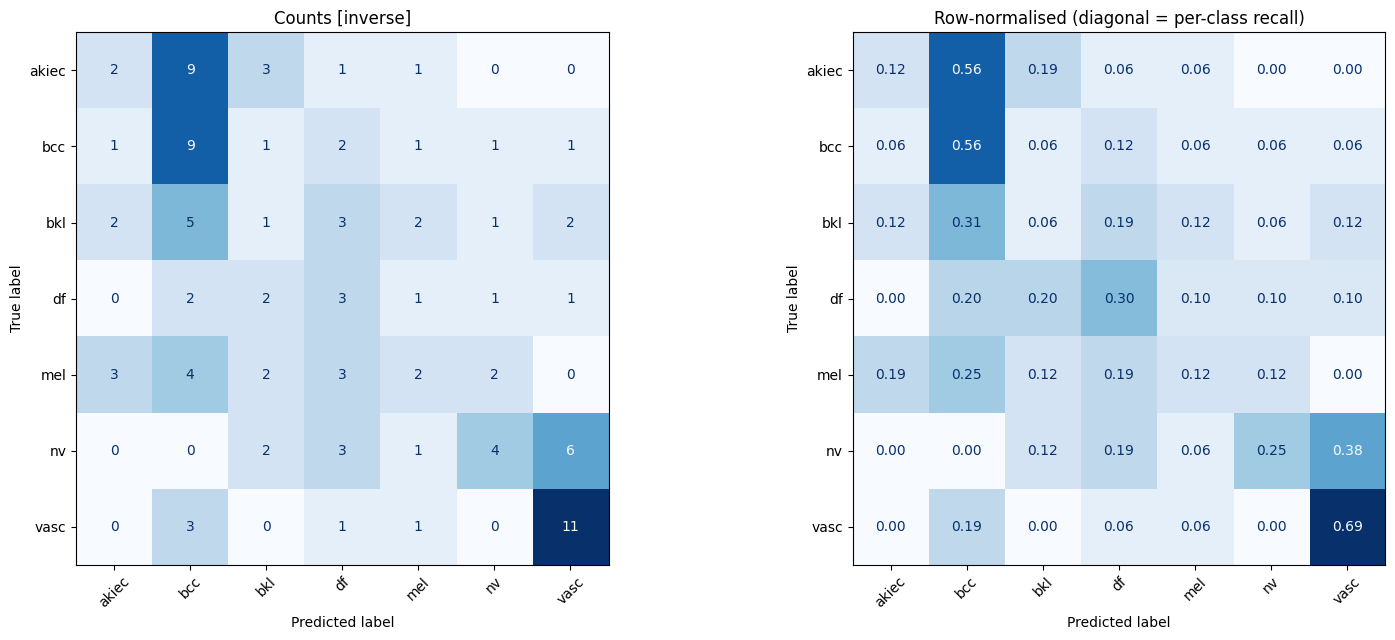

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

model.load_state_dict(best_state)
test_logits, test_y = predict(test_loader)
val_logits, val_y = predict(val_loader)
y_true, y_pred = test_y.numpy(), test_logits.argmax(1).numpy()
y_probs = torch.softmax(test_logits, dim=1).numpy()
val_probs = torch.softmax(val_logits, dim=1).numpy()

acc = accuracy_score(y_true, y_pred)
bal = balanced_accuracy_score(y_true, y_pred)
mf1 = f1_score(y_true, y_pred, average="macro", labels=list(range(K)), zero_division=0)
recalls = recall_score(y_true, y_pred, labels=list(range(K)), average=None, zero_division=0)
try:
    auc = roc_auc_score(y_true, y_probs, multi_class="ovr", average="macro", labels=list(range(K)))
except ValueError as e:
    auc = float("nan"); print("AUC not computed:", e)

print(f"[{WEIGHT_MODE}] best epoch {best_epoch}")
print(f"Test Accuracy:     {acc:.4f}")
print(f"Balanced Accuracy: {bal:.4f}")
print(f"Macro F1-score:    {mf1:.4f}")
print(f"Melanoma recall:   {recalls[mel_idx]:.4f}")
print(f"Macro ROC-AUC:     {auc:.4f}\n")
print(classification_report(y_true, y_pred, labels=list(range(K)), target_names=classes, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
cm = confusion_matrix(y_true, y_pred, labels=list(range(K)))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[0], cmap="Blues", xticks_rotation=45, values_format="d", colorbar=False)
ax[0].set_title(f"Counts [{WEIGHT_MODE}]")
cmn = confusion_matrix(y_true, y_pred, labels=list(range(K)), normalize="true")
ConfusionMatrixDisplay(cmn, display_labels=classes).plot(ax=ax[1], cmap="Blues", xticks_rotation=45, values_format=".2f", colorbar=False)
ax[1].set_title("Row-normalised (diagonal = per-class recall)")
plt.tight_layout(); plt.show()

In [13]:
os.makedirs(OUT_DIR, exist_ok=True)
tag = f"{WEIGHT_MODE}_seed{SEED}" + ("_DRYRUN" if DRY_RUN else "")

results = {
    "tag": tag, "weight_mode": WEIGHT_MODE, "seed": SEED, "dry_run": DRY_RUN, "best_epoch": int(best_epoch),
    "config": dict(epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, weight_decay=WEIGHT_DECAY, img_size=IMG_SIZE,
                   eff_beta=EFF_BETA, split_dir=SPLIT_DIR),
    "class_weights": dict(zip(classes, [float(w) for w in class_weights])),
    "train_counts": dict(zip(classes, [int(c) for c in counts])),
    "test": {"accuracy": float(acc), "balanced_accuracy": float(bal), "macro_f1": float(mf1), "macro_auc": float(auc),
             "recall": dict(zip(classes, [float(r) for r in recalls])), "confusion": cm.tolist()},
    "best_val_macro_f1": float(best_f1),
    "history": history,
    "env": {"torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
}
with open(f"{OUT_DIR}/results_{tag}.json", "w") as f:
    json.dump(results, f, indent=2)
np.savez(f"{OUT_DIR}/probs_{tag}.npz", val_probs=val_probs, val_y=val_y.numpy(), test_probs=y_probs, test_y=y_true)
if not DRY_RUN:
    torch.save({"model_state_dict": best_state, "class_to_idx": class_to_idx, "best_epoch": best_epoch},
               f"{OUT_DIR}/best_{tag}.pth")
print("Saved results (and probabilities) to", OUT_DIR, "| tag:", tag)

Saved results (and probabilities) to /content/drive/MyDrive/HAM10000_model/imbalance_runs | tag: inverse_seed42_DRYRUN


## 6 · Compare everything saved so far
Run this after you have run several `WEIGHT_MODE`s (it only reads files; no training). The first row is your original baseline, shown for reference only: it had no augmentation and selected by validation loss, so use the `none` row from this notebook for a fair comparison.

With only ~10 test images for `df` and 16 for `vasc`, one image changes those recalls by 10 and 6 points. Treat small differences as noise until repeated over several seeds or splits.

In [14]:
rows = [{"run": "ORIGINAL baseline (no aug, val-loss select)", "acc": 0.8307, "bal_acc": 0.6504, "macro_f1": 0.6542,
         "auc": 0.9609, "mel_rec": 0.5625, "df_rec": 0.2000, "akiec_rec": 0.5122, "best_ep": 2}]
for f in sorted(glob.glob(f"{OUT_DIR}/results_*.json")):
    r = json.load(open(f))
    if r.get("dry_run"):
        continue
    t = r["test"]
    rows.append({"run": r["tag"], "acc": t["accuracy"], "bal_acc": t["balanced_accuracy"], "macro_f1": t["macro_f1"],
                 "auc": t["macro_auc"], "mel_rec": t["recall"]["mel"], "df_rec": t["recall"]["df"],
                 "akiec_rec": t["recall"]["akiec"], "best_ep": r["best_epoch"]})
cmp_df = pd.DataFrame(rows)
print(cmp_df.round(4).to_string(index=False))

                                        run    acc  bal_acc  macro_f1    auc  mel_rec  df_rec  akiec_rec  best_ep
ORIGINAL baseline (no aug, val-loss select) 0.8307   0.6504    0.6542 0.9609   0.5625     0.2     0.5122        2
